# UPA – projekt 2: príprava dvoch variantov datasetu

Tento notebook je **návod aj riešenie**: pri každom kroku je napísané *čo* sa robí, *ako* a hlavne *prečo*. Dáta sú z `data.tsv` (pneumatiky zo simpletire.com).

## Čo zadanie chce (časť „Připravte 2 varianty datové sady“)

| # | Požiadavka zadania | Kde |
|---|---|---|
| 1 | Odstrániť irelevantné atribúty; pokiaľ sa dá, nechať kategorické **aj** numerické, atribúty s NaN aj s odľahlými hodnotami | §6 |
| 2 | Vyriešiť chýbajúce hodnoty **aspoň dvomi rôznymi metódami** | §3–§4 |
| 3 | Vyriešiť odľahlé hodnoty | §5, §8 |
| 4 | **Variant A:** diskretizácia numerických atribútov (pre algoritmy, ktoré chcú kategorický vstup) | §7 |
| 5 | **Variant B:** kategorické → numerické + normalizácia atribútov mimo `<0,1>` / `<-1,1>` | §8 |

Výstup: dva CSV súbory + PDF dokumentácia (pri každej úprave: *metóda + zdôvodnenie*, bez zdrojového kódu).

## Prečo je poradie krokov také, aké je
1. Najprv sa dáta **rozparsujú a vyčistia** (z textu `"$273.80"` číslo).
2. Potom **chýbajúce hodnoty** – každý ďalší krok (odľahlé hodnoty, škálovanie, intervaly) potrebuje kompletné hodnoty.
3. Potom **odľahlé hodnoty**, kým sú čísla ešte v pôvodných jednotkách (USD, mm) a dajú sa čítať.
4. Až **nakoniec** diskretizácia (A) a kódovanie + normalizácia (B). Keby sa normalizovalo skôr, odľahlá hodnota by roztiahla rozsah (min–max) a všetko ostatné by sa stlačilo do úzkeho pásu.

## Dolovacie úlohy (zadanie dovoľuje zvoliť vlastnú)
- **Variant A (kategorický):** klasifikácia **cenovej triedy** (nízka / stredná / vysoká) – napr. rozhodovací strom, naive Bayes, asociačné pravidlá.
- **Variant B (numerický):** **predikcia ceny** (regresia), prípadne zhlukovanie podobných pneumatík.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

pd.set_option("display.width", 150); pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
DATA = "data.tsv"          # cesta k dátam z 1. časti projektu

## §1 Načítanie

TSV z 1. časti **nemá hlavičku**, preto stĺpce pomenujeme sami (význam je v README z 1. časti).

**Prečo `dtype=str, keep_default_na=False`:** pandas by inak sám hádal typy a prázdny reťazec by potichu zmenil na NaN. My chceme **vidieť surové hodnoty** a o typoch rozhodnúť vedome (zadanie 1. časti navyše hovorí, že hodnoty sú reťazce).

In [2]:
COLS = ["url", "name", "price", "width", "ratio", "pressure", "tread", "sidewall"]
raw = pd.read_csv(DATA, sep="\t", header=None, names=COLS, dtype=str, keep_default_na=False)
print("tvar:", raw.shape)
display(raw.head(3))
print("prázdne reťazce v surových dátach (na stĺpec):")
print((raw == "").sum().to_string())

tvar: (150, 8)


,url,name,price,width,ratio,pressure,tread,sidewall
0,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$485.99,LT37,13.50R,50,22.00,Blackwall
1,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$481.99,LT37,13.50R,50,22.00,Blackwall
2,https://simpletire.com/brands/mickey-thompson-...,Mickey Thompson Baja Legend MTZ,$346.96,LT315,70R,65,21.00,Raised White Lettering


prázdne reťazce v surových dátach (na stĺpec):
url         0
name        0
price       0
width       0
ratio       0
pressure    0
tread       0
sidewall    0


## §2 Čistenie a odvodené atribúty

**Čo:** z textov vyrobíme čísla a z URL / hodnôt odvodíme kategórie.
**Prečo:** algoritmy a grafy nevedia pracovať s `"$273.80"` alebo `"LT285"`.

| pôvodný stĺpec | čo z neho robíme |
|---|---|
| `url` | `brand`, `model` (z cesty `/brands/<brand>-tires/<model>`), `size` a **`rim`** (priemer ráfika je len v URL, napr. `tireSize=255-70rr17`; pozor na `…rr16c` – písmeno `c` = dodávkové pneumatiky) |
| `price` | `price_usd` (číslo bez `$`) |
| `width` | `is_LT` (začína `LT` = light truck) + číselná šírka |
| `ratio` | číselný profil (`70R`, `45ZR` → 70, 45) + príznak **`flotation`** |
| `pressure`, `tread` | čísla |

### Pasca: flotation rozmery
Bežný rozmer `255/70R17` = šírka **255 mm**, profil **70 %**. Ale `LT37 × 13.50R18` je v **palcoch**: 37 = vonkajší priemer, 13,50 = šírka. Čísla `37` a `13.5` by sa nesmeli miešať s mm a % – pokazili by korelácie aj grafy. Preto ich **nevkladáme do `width_mm` / `ratio_pct`** (tam budú NaN) a uložíme zvlášť v palcoch. Flotation rozpoznáme podľa desatinnej bodky v `ratio`.

In [3]:
df = pd.DataFrame(index=raw.index)
df["url"], df["name"] = raw["url"], raw["name"]

bm = raw["url"].str.extract(r"/brands/([a-z0-9-]+)-tires/([^#]+)#")
df["brand"], df["model"] = bm[0], bm[1]
df["size"] = raw["url"].str.extract(r"tireSize=([^&]*)")[0]
df["rim"] = df["size"].str.extract(r"(\d+)c?$")[0].astype(float)

df["price_usd"]    = raw["price"].str.replace(r"[^0-9.]", "", regex=True).astype(float)
df["is_LT"]        = raw["width"].str.startswith("LT").astype(int)
df["flotation"]    = raw["ratio"].str.contains(r"\.", regex=True).astype(int)
width_num = pd.to_numeric(raw["width"].str.replace("LT", "", regex=False))
ratio_num = pd.to_numeric(raw["ratio"].str.replace(r"[A-Z]+$", "", regex=True))

# metrické rozmery: šírka v mm, profil v %.  flotation rozmery: obe čísla sú v palcoch -> do mm/% ich nedávame
is_fl = df["flotation"] == 1
df["width_mm"]       = width_num.where(~is_fl)
df["ratio_pct"]      = ratio_num.where(~is_fl)
df["fl_diameter_in"] = width_num.where(is_fl)     # napr. 37
df["fl_width_in"]    = ratio_num.where(is_fl)     # napr. 13.5

df["pressure_psi"] = pd.to_numeric(raw["pressure"])
df["tread_32"]     = pd.to_numeric(raw["tread"])
df["sidewall"]     = raw["sidewall"]

print("brand:", df["brand"].nunique(), "| model:", df["model"].nunique(),
      "| LT:", int(df.is_LT.sum()), "| flotation:", int(df.flotation.sum()),
      "| rim chýba:", int(df.rim.isna().sum()))
display(df[["brand","model","size","price_usd","is_LT","flotation","width_mm","ratio_pct","fl_diameter_in","fl_width_in","rim"]].iloc[[0, 2, 12, 100]])

brand: 6 | model: 8 | LT: 68 | flotation: 22 | rim chýba: 0


,brand,model,size,price_usd,is_LT,flotation,width_mm,ratio_pct,fl_diameter_in,fl_width_in,rim
0,mickey-thompson,baja-legend-mtz,lt37-13.50rr18,485.99,1,1,NaN,NaN,37.0,13.5,18.0
2,mickey-thompson,baja-legend-mtz,lt315-70rr17,346.96,1,0,315.0,70.0,NaN,NaN,17.0
12,mickey-thompson,baja-legend-mtz,lt37-12.50rr17,484.99,1,1,NaN,NaN,37.0,12.5,17.0
100,toyo,celsius-cargo,225-75rr16c,189.25,0,0,225.0,75.0,NaN,NaN,16.0


### Duplicity
Ten istý model a rozmer s iným `mpn` (číslo výrobcu) je takmer určite tá istá pneumatika (rovnaká cena, parametre). Do tréningu aj testu by sa dostala dvakrát a model by ju „poznal“ → zavádzajúce výsledky. **Necháme prvý výskyt.** Rozhodnutie je na tebe (v dokumentácii ho zdôvodni); dokážeme ho ale ukázať číslom.

In [4]:
key = ["model", "size"]
display(df[df.duplicated(key, keep=False)][key + ["price_usd", "url"]].assign(url=lambda d: d.url.str.extract(r"mpn=(\d+)")[0]).rename(columns={"url": "mpn"}))
n_dup = int(df.duplicated(key, keep="first").sum())
df = df[~df.duplicated(key, keep="first")].reset_index(drop=True)
print(f"odstránené duplicity: {n_dup} | zostáva riadkov: {len(df)}")

,model,size,price_usd,mpn
2,baja-legend-mtz,lt315-70rr17,346.96,331136011
4,baja-legend-mtz,lt275-70rr18,289.96,331129011
6,baja-legend-mtz,lt315-70rr17,346.96,331278011
24,baja-legend-mtz,lt275-70rr18,289.96,331302011


odstránené duplicity: 2 | zostáva riadkov: 148


## §3 Analýza chýbajúcich hodnôt (zadanie, bod 4 EDA)

Zadanie chce: **celkový počet NaN, počet objektov s viacerými NaN** atď. V surových dátach sme videli 0 prázdnych hodnôt – ale po rozparsovaní (§2) **vznikli NaN v `width_mm` a `ratio_pct`**. To je poctivá situácia: chýbanie **nie je v zdroji, vzniklo pri čistení**, a má jasnú príčinu (flotation rozmery sú v inej jednotke). V dokumentácii to tak aj napíš.

NaN na stĺpec:
price_usd        0
width_mm        22
ratio_pct       22
rim              0
pressure_psi     0
tread_32         0

celkom NaN buniek: 44 z 888 (5.0%)
riadky podľa počtu NaN: {0: 126, 2: 22}
sú NaN riadky presne flotation riadky? True


,,riadkov s NaN
brand,model,
kumho,road-venture-rt51,8
mickey-thompson,baja-legend-mtz,13
pirelli,scorpion-xtm-at,1


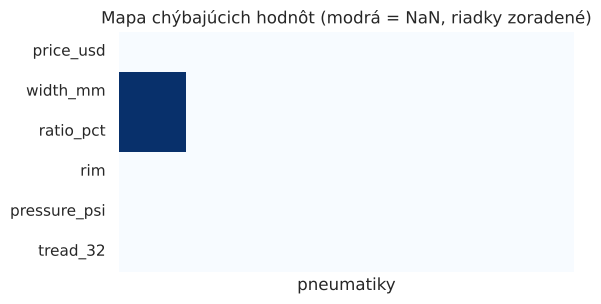

In [5]:
NUM = ["price_usd", "width_mm", "ratio_pct", "rim", "pressure_psi", "tread_32"]
miss = df[NUM].isna()
print("NaN na stĺpec:\n" + miss.sum().to_string())
miss_cells = int(miss.values.sum())
print(f"\ncelkom NaN buniek: {miss_cells} z {miss.size} ({miss_cells / miss.size:.1%})")
per_row = miss.sum(axis=1)
print("riadky podľa počtu NaN:", per_row.value_counts().sort_index().to_dict())
print("sú NaN riadky presne flotation riadky?", bool((miss.any(axis=1) == (df.flotation == 1)).all()))
display(df[miss.any(axis=1)].groupby(["brand", "model"]).size().rename("riadkov s NaN").to_frame())

plt.figure(figsize=(6, 3.2))
sns.heatmap(miss.sort_values(NUM, ascending=False).reset_index(drop=True).T, cbar=False, cmap="Blues", yticklabels=True, xticklabels=False)
plt.title("Mapa chýbajúcich hodnôt (modrá = NaN, riadky zoradené)"); plt.xlabel("pneumatiky"); plt.tight_layout(); plt.show()

**Čo z toho vyčítať:** NaN sú vždy **v dvojici** (šírka aj profil naraz) a vždy práve v riadkoch s `flotation = 1`. Chýbanie teda **nie je náhodné**, ale úplne vysvetlené iným atribútom. To je dôležité pre výber metódy: nemá zmysel dopĺňať „priemerom všetkých pneumatík“ – vieme presne, **prečo** hodnota chýba, a čiastočne aj **ako** ju dopočítať.

## §4 Dve metódy riešenia chýbajúcich hodnôt

### Metóda 1 – doménový prepočet (deterministická)
Flotation rozmer je v palcoch, tak ho prepočítame na metrický:
- **šírka [mm]** = šírka v palcoch × 25,4
- **profil [%]** = výška bočnice / šírka × 100, kde výška bočnice = (vonkajší priemer − priemer ráfika) / 2 (priemer ráfika máme z URL)

*Prečo:* keď existuje fyzikálne pravidlo, je presnejšie než akýkoľvek odhad z ostatných riadkov. Obmedzenie: vonkajší priemer v názve je **nominálny**, skutočný sa môže líšiť, preto je profil približný.

### Metóda 2 – kNN imputácia
Chýbajúcu hodnotu odhadne z **k najpodobnejších pneumatík** (priemer ich hodnôt).
- **Prečo najprv škálovať:** kNN počíta vzdialenosti. Bez škálovania by `rim` (15–22) a `pressure` (35–83) rozhodovali o „podobnosti“ úplne inak než `is_LT` (0/1).
- **Prečo bez ceny medzi vstupmi:** ak je cieľ úlohy predikcia ceny, nesmie sa cena použiť na doplnenie vstupov – do vstupov by presiakla informácia o cieli (*data leakage*).

In [6]:
# --- Metóda 1: prepočet
f = df["flotation"] == 1
df["width_conv"], df["ratio_conv"] = df["width_mm"], df["ratio_pct"]
df.loc[f, "width_conv"] = (df.loc[f, "fl_width_in"] * 25.4).round()
sidewall_in = (df.loc[f, "fl_diameter_in"] - df.loc[f, "rim"]) / 2
df.loc[f, "ratio_conv"] = (sidewall_in / df.loc[f, "fl_width_in"] * 100).round()

# --- Metóda 2: kNN (škálovanie -> imputácia -> späť na pôvodné jednotky)
FEAT, TARGETS = ["rim", "pressure_psi", "tread_32", "is_LT"], ["width_mm", "ratio_pct"]
def knn_impute(d, k=5):
    sub = d[FEAT + TARGETS]
    sc = MinMaxScaler().fit(sub)
    filled = KNNImputer(n_neighbors=k).fit_transform(sc.transform(sub))
    return pd.DataFrame(sc.inverse_transform(filled), columns=sub.columns, index=d.index)

knn = knn_impute(df)
df["width_knn"], df["ratio_knn"] = knn["width_mm"], knn["ratio_pct"]
display(df.loc[f, ["size", "width_conv", "width_knn", "ratio_conv", "ratio_knn"]].round(1).head(8))

,size,width_conv,width_knn,ratio_conv,ratio_knn
0,lt37-13.50rr18,343.0,307.0,70.0,71.0
1,lt37-13.50rr17,343.0,307.0,74.0,71.0
3,lt33-12.50rr20,318.0,299.0,52.0,61.0
5,lt33-10.50rr15,267.0,301.0,86.0,72.0
6,lt31-10.50rr15,267.0,301.0,76.0,72.0
11,lt37-12.50rr17,318.0,307.0,80.0,71.0
12,lt38-15.50rr20,394.0,299.0,58.0,61.0
15,lt40-13.50rr17,343.0,307.0,85.0,71.0


### Ktorá metóda je lepšia? Meranie, nie dojem
Dve kontroly:
1. **Maskovací test:** zo známych hodnôt (metrické rozmery) 15 náhodne schováme, doplníme ich a porovnáme so skutočnosťou. Porovnáme kNN s najjednoduchším základom – **mediánom**.
2. **Na skutočných flotation riadkoch:** porovnáme kNN s prepočtom (prepočet berieme za referenciu).

1) Maskovací test – priemerná absolútna chyba (width v mm, ratio v p. b.):


,MAE medián,MAE kNN
width_mm,27.2,12.0
ratio_pct,10.0,5.2


2) Flotation riadky: kNN vs. prepočet – MAE šírka 36.5 mm, profil 5.5 p. b.


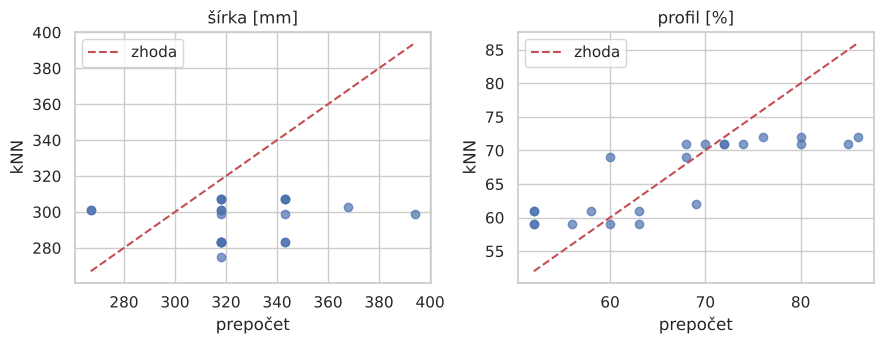

In [7]:
def masked_test(target, n_mask=15, reps=30, seed=0):
    rng = np.random.default_rng(seed)
    known = df.index[df[target].notna()]
    e_med, e_knn = [], []
    for _ in range(reps):
        m = rng.choice(known, size=n_mask, replace=False)
        d = df.copy(); truth = d.loc[m, target].copy(); d.loc[m, target] = np.nan
        e_med.append((truth - d[target].median()).abs().mean())
        e_knn.append((truth - knn_impute(d).loc[m, target]).abs().mean())
    return np.mean(e_med), np.mean(e_knn)

res = {}
for t in TARGETS:
    res[t] = masked_test(t)
test = pd.DataFrame(res, index=["medián", "kNN"]).T.round(1)
test.columns = ["MAE medián", "MAE kNN"]
print("1) Maskovací test – priemerná absolútna chyba (width v mm, ratio v p. b.):")
display(test)

mae_w = (df.loc[f, "width_knn"] - df.loc[f, "width_conv"]).abs().mean()
mae_r = (df.loc[f, "ratio_knn"] - df.loc[f, "ratio_conv"]).abs().mean()
print(f"2) Flotation riadky: kNN vs. prepočet – MAE šírka {mae_w:.1f} mm, profil {mae_r:.1f} p. b.")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, (c, k, t) in zip(ax, [("width_conv", "width_knn", "šírka [mm]"), ("ratio_conv", "ratio_knn", "profil [%]")]):
    a.scatter(df.loc[f, c], df.loc[f, k], alpha=.7)
    lo, hi = min(df.loc[f, c].min(), df.loc[f, k].min()), max(df.loc[f, c].max(), df.loc[f, k].max())
    a.plot([lo, hi], [lo, hi], "r--", label="zhoda"); a.set_xlabel("prepočet"); a.set_ylabel("kNN"); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

**Ako to čítať:**
- Na **bežných** rozmeroch je kNN výrazne presnejší než medián (menšia chyba) → kNN je rozumná všeobecná metóda.
- Na **flotation** riadkoch ale kNN **nedoženie** prepočet: tieto pneumatiky majú systematicky iné (širšie) rozmery než všetko, z čoho kNN odhaduje, a kNN **nevie extrapolovať** za to, čo vidí.
- **Záver pre dokumentáciu:** ak existuje presné pravidlo, je lepšie ako odhad. Zadanie ale chce dve rôzne metódy, preto ich rozdelíme medzi varianty: **A dostane prepočet, B dostane kNN**, a kvalitu porovnáme čísla vyššie. (Keby si chcel čo najlepšie dáta, použi prepočet v oboch.)

## §5 Odľahlé hodnoty (zadanie: skúsiť viac spôsobov)

Použijeme **štyri** spôsoby, lebo každý hľadá niečo iné:

| metóda | čo je „odľahlé“ | slabina |
|---|---|---|
| **IQR** (Tukey) | mimo `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` | funguje po jednom atribúte; nevidí nezvyčajné *kombinácie* |
| **z-skóre** | `|z| > 3` (vzdialenosť od priemeru v smerodajných odchýlkach) | sám odľahlý bod ťahá priemer a smerodajnú odchýlku; predpokladá približne symetrické rozdelenie |
| **Isolation Forest** | body, ktoré sa dajú „izolovať“ pár náhodnými rezmi | `contamination` (podiel odľahlých) musíme odhadnúť |
| **LOF** (Local Outlier Factor) | body s menšou hustotou než ich susedia | počíta vzdialenosti → **vyžaduje škálované dáta** |

Používame hodnoty po prepočte (`width_conv`, `ratio_conv`), aby boli všetky riadky kompletné.

,atribút,IQR_dolná,IQR_horná,n_IQR,n_z_nad_3,n_z_nad_2_5
0,price_usd,-104.0,650.0,0,0,2
1,width_conv,153.8,363.8,2,1,2
2,ratio_conv,20.0,100.0,0,0,0
3,rim,14.0,22.0,0,0,2
4,pressure_psi,5.0,125.0,0,0,0
5,tread_32,1.5,26.8,0,0,0


Isolation Forest: 8 | LOF: 8 | oboje: 3


,brand,model,size,price_usd,pressure_psi,tread_32,out_iso,out_lof
12,mickey-thompson,baja-legend-mtz,lt38-15.50rr20,642.99,65,21.0,True,True
15,mickey-thompson,baja-legend-mtz,lt40-13.50rr17,578.99,35,22.0,True,False
25,mickey-thompson,baja-legend-mtz,lt40-14.50rr20,644.99,50,22.0,True,False
26,mickey-thompson,baja-legend-mtz,lt35-12.50rr15,389.99,35,21.0,True,False
47,kumho,road-venture-rt51,lt35-12.50rr22,548.00,80,17.3,True,False
48,kumho,road-venture-rt51,lt37-13.50rr22,543.99,80,17.3,True,False
57,kumho,road-venture-at52,245-70rr16,184.68,50,13.5,False,True
99,toyo,celsius-cargo,185-60rr15c,143.34,54,12.1,True,True
131,toyo,proxes-sport-r,335-30zrr18,482.79,51,7.2,True,True
132,toyo,proxes-sport-r,265-35zrr18,364.84,50,7.2,False,True


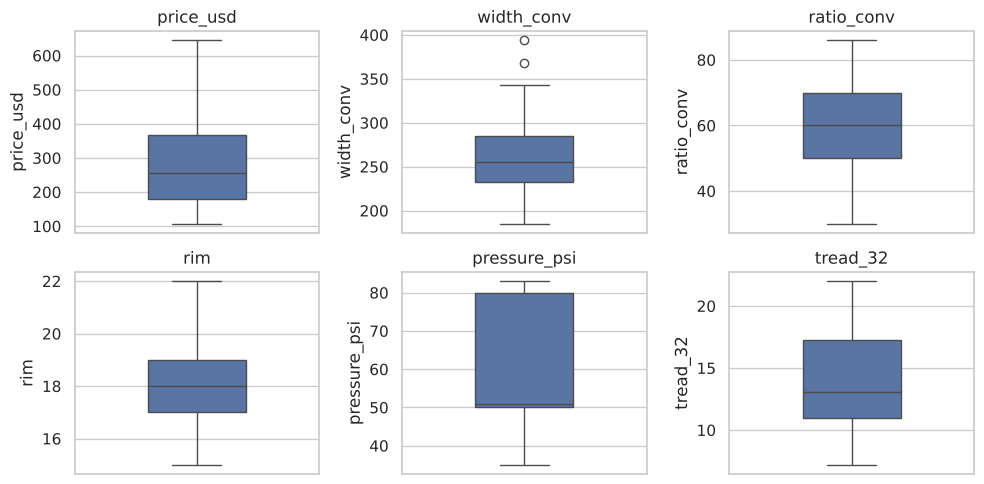

In [8]:
NUMC = ["price_usd", "width_conv", "ratio_conv", "rim", "pressure_psi", "tread_32"]

def iqr_fences(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return q1 - 1.5 * i, q3 + 1.5 * i

rows = []
for c in NUMC:
    lo, hi = iqr_fences(df[c]); z = (df[c] - df[c].mean()) / df[c].std()
    rows.append(dict(atribút=c, IQR_dolná=lo, IQR_horná=hi, n_IQR=int(((df[c] < lo) | (df[c] > hi)).sum()),
                     n_z_nad_3=int((z.abs() > 3).sum()), n_z_nad_2_5=int((z.abs() > 2.5).sum())))
out_tab = pd.DataFrame(rows).round(1)
display(out_tab)

Xs = MinMaxScaler().fit_transform(df[NUMC])      # LOF potrebuje škálované dáta
df["out_iso"] = IsolationForest(contamination=0.05, random_state=0).fit_predict(Xs) == -1
df["out_lof"] = LocalOutlierFactor(n_neighbors=10, contamination=0.05).fit_predict(Xs) == -1
print(f"Isolation Forest: {int(df.out_iso.sum())} | LOF: {int(df.out_lof.sum())} | oboje: {int((df.out_iso & df.out_lof).sum())}")
display(df.loc[df.out_iso | df.out_lof, ["brand", "model", "size", "price_usd", "pressure_psi", "tread_32", "out_iso", "out_lof"]])

fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for a, c in zip(axes.flat, NUMC):
    sns.boxplot(y=df[c], ax=a, width=.4); a.set_title(c)
plt.tight_layout(); plt.show()

**Ako to čítať a čo s tým:**
- **Jednorozmerné metódy (IQR, z-skóre)** nájdu len málo, prípadne nič – najmä v cene. Samotná vysoká cena (napr. 645 USD) ešte nie je anomália, ak je to veľká terénna pneumatika.
- **Viacrozmerné metódy (IF, LOF)** označia body, ktoré sú **zvláštne v kombinácii** atribútov – a, dôležité, **sú zhodné len čiastočne** (každá meria „odľahlosť“ inak). Nezhoda dvoch metód je normálna a v dokumentácii sa o nej oplatí zmieniť.
- Označené body sú podľa tabuľky **skupiny reálnych produktov, ktoré sa líšia od zvyšku** (napr. všetky Toyo Proxes Sport R majú behúň 7,2 a rozmery ZR; veľké LT pneumatiky Mickey Thompson majú behúň 21–22), nie chyby merania. *(Z dát nevieme povedať, o aký „typ“ pneumatiky ide – to by bola domnienka.)*
- **Odľahlá ≠ chybná.** Odstránenie by z 148 riadkov vyhodilo celé skupiny reálnych produktov. Preto: **Variant A** – diskretizácia podľa kvantilov je voči odľahlým hodnotám prirodzene odolná (extrém spadne do poslednej triedy). **Variant B** – *winsorizácia* (orezanie na hranice IQR) sa naprogramuje, ale na týchto dátach pravdepodobne **nezmení nič** (pozri §8) – a to je legitímny výsledok. Odstránenie riadkov uvedieme v dokumentácii ako zvažovanú, ale nepoužitú metódu (dôvod: malý dataset, reálne dáta).
- **Zaujímavosť:** IQR označil len 2 šírky – a to **po prepočte** flotation rozmerov (tie sú najširšie). Po kNN imputácii (variant B) takéto široké hodnoty nevzniknú. **Počet odľahlých hodnôt teda závisí od zvolenej metódy imputácie** – dobrý bod do dokumentácie.

## §6 Výber atribútov (odstránenie irelevantných)

| atribút | rozhodnutie | prečo |
|---|---|---|
| `url`, `name` | **preč** | identifikátory; nenesú informáciu o vlastnostiach, každý riadok je iný |
| `size`, pomocné stĺpce | **preč** | len medzikrok; informácia je v `width`, `ratio`, `rim` |
| `sidewall` | **preč** | takmer konštanta (jedna hodnota skoro vo všetkých riadkoch) – nemá z čoho „sa učiť“ |
| `model` | **preč** | je vnorený do `brand` (každý model patrí jednej značke) a niektoré modely majú 2–5 riadkov |
| `brand` | **ostáva** (kategorický) | 6 hodnôt, štyri s 30 riadkami |
| `is_LT`, `flotation` | **ostávajú** (kategorické, binárne) | vysvetľujú rozdiely v cene aj v rozmeroch |
| `price_usd`, `width`, `ratio`, `rim`, `pressure_psi`, `tread_32` | **ostávajú** (numerické) | |

Zadanie chce nechať kategorické aj numerické, a to aj atribúty s NaN a odľahlými hodnotami – tie ostávajú.

In [9]:
print("sidewall:", df["sidewall"].value_counts().to_dict())
print("model -> koľko značiek (max):", int(df.groupby("model")["brand"].nunique().max()))
print("riadkov na model:", df["model"].value_counts().to_dict())

sidewall: {'Blackwall': 147, 'Raised White Lettering': 1}
model -> koľko značiek (max): 1
riadkov na model: {'assurance-comfortdrive': 30, 'ziex-ze960-a-s': 30, 'baja-legend-mtz': 28, 'road-venture-rt51': 28, 'celsius-cargo': 13, 'scorpion-xtm-at': 12, 'proxes-sport-r': 5, 'road-venture-at52': 2}


## §7 Variant A – diskretizácia (kategorický dataset)

**Cieľ:** všetky atribúty kategorické, aby sa dali použiť napr. v rozhodovacom strome, naive Bayes alebo pri asociačných pravidlách.

Dve základné stratégie intervalov:
- **Equal-width** (rovnaká šírka): rozsah sa rozseká na rovnako široké pásma. Jednoduché, ale pri šikmom rozdelení (veľa lacných, málo drahých) sú niektoré triedy skoro prázdne.
- **Equal-frequency** (kvantily): v každej triede približne rovnaký počet riadkov. Odolné voči odľahlým hodnotám a vyvážené triedy.

Pozri rozdiel na cene:

In [10]:
price = df["price_usd"]
print("equal-width (3 pásma):");     display(pd.cut(price, 3).value_counts().sort_index().to_frame("počet"))
print("equal-frequency (3 kvantily):"); display(pd.qcut(price, 3).value_counts().sort_index().to_frame("počet"))

equal-width (3 pásma):


,počet
price_usd,
"(106.462, 286.33]",83
"(286.33, 465.66]",49
"(465.66, 644.99]",16


equal-frequency (3 kvantily):


,počet
price_usd,
"(106.999, 194.99]",50
"(194.99, 338.66]",49
"(338.66, 644.99]",49


**Voľba:** kvantily pre `price`, `width`, `ratio`, `rim`, `tread` (vyvážené triedy, odolné voči extrémom).
**Výnimka – `pressure`:** má len pár rôznych hodnôt (35, 44, 50, 51, 54, 65, 69, 76, 80, 83) a väčšina riadkov leží na 50 alebo 51 PSI. Pozri, kam by padli kvantilové hranice:

In [11]:
pq, edges = pd.qcut(df["pressure_psi"], 3, retbins=True, duplicates="drop")
print("hranice qcut(pressure, 3):", edges)
display(pd.crosstab(pq, df["pressure_psi"]))

hranice qcut(pressure, 3): [35. 50. 69. 83.]


pressure_psi,35,44,50,51,54,65,69,76,80,83
pressure_psi,,,,,,,,,,
"(34.999, 50.0]",2,3,49,0,0,0,0,0,0,0
"(50.0, 69.0]",0,0,0,33,1,10,1,0,0,0
"(69.0, 83.0]",0,0,0,0,0,0,0,1,46,2


Hranica padne **medzi 50 a 51 PSI** – prakticky rovnaké pneumatiky by skončili v rôznych triedach len preto, že kvantil „trafil“ doprostred zhluku rovnakých hodnôt. Hranice preto určíme **ručne z viditeľných medzier** v hodnotách (≤ 60 / 61–75 / > 75).

In [12]:
base = pd.DataFrame({
    "brand": df["brand"],
    "is_LT": df["is_LT"].map({0: "nie", 1: "áno"}),
    "flotation": df["flotation"].map({0: "nie", 1: "áno"}),
    "price_usd": df["price_usd"], "width_mm": df["width_conv"], "ratio_pct": df["ratio_conv"],       # metóda 1: prepočet
    "rim": df["rim"], "pressure_psi": df["pressure_psi"], "tread_32": df["tread_32"],
})

A = base[["brand", "is_LT", "flotation"]].copy()
A["price_class"]  = pd.qcut(base["price_usd"], 3, labels=["nízka", "stredná", "vysoká"])
A["width_class"]  = pd.qcut(base["width_mm"], 3, labels=["úzka", "stredná", "široká"])
A["ratio_class"]  = pd.qcut(base["ratio_pct"], 3, labels=["nízky", "stredný", "vysoký"])
A["rim_class"]    = pd.qcut(base["rim"], 3, labels=["malý", "stredný", "veľký"])
A["tread_class"]  = pd.qcut(base["tread_32"], 3, labels=["plytký", "stredný", "hlboký"])
A["pressure_class"] = pd.cut(base["pressure_psi"], [0, 60, 75, 200], labels=["nízky (≤60)", "stredný (61–75)", "vysoký (>75)"])
A = A.astype(str)

# hranice intervalov (to patrí do dokumentácie)
for c, col in [("price_usd", "price_class"), ("width_mm", "width_class"), ("ratio_pct", "ratio_class"), ("rim", "rim_class"), ("tread_32", "tread_class")]:
    print(f"{col:12s} hranice kvantilov:", [round(x, 1) for x in base[c].quantile([0, 1/3, 2/3, 1]).tolist()])
print()
display(A.head())
print("počet unikátnych hodnôt:", A.nunique().to_dict())
print("nechýba nič:", int(A.isna().sum().sum()) == 0)

price_class  hranice kvantilov: [107.0, 195.0, 338.7, 645.0]
width_class  hranice kvantilov: [185.0, 245.0, 275.0, 394.0]
ratio_class  hranice kvantilov: [30.0, 55.0, 65.0, 86.0]
rim_class    hranice kvantilov: [15.0, 17.0, 18.0, 22.0]
tread_class  hranice kvantilov: [7.2, 11.0, 17.3, 22.0]



,brand,is_LT,flotation,price_class,width_class,ratio_class,rim_class,tread_class,pressure_class
0,mickey-thompson,áno,áno,vysoká,široká,vysoký,stredný,hlboký,nízky (≤60)
1,mickey-thompson,áno,áno,vysoká,široká,vysoký,malý,hlboký,nízky (≤60)
2,mickey-thompson,áno,nie,vysoká,široká,vysoký,malý,hlboký,stredný (61–75)
3,mickey-thompson,áno,áno,vysoká,široká,nízky,veľký,hlboký,stredný (61–75)
4,mickey-thompson,áno,nie,stredná,stredná,vysoký,stredný,hlboký,vysoký (>75)


počet unikátnych hodnôt: {'brand': 6, 'is_LT': 2, 'flotation': 2, 'price_class': 3, 'width_class': 3, 'ratio_class': 3, 'rim_class': 3, 'tread_class': 3, 'pressure_class': 3}
nechýba nič: True


## §8 Variant B – numerický dataset (kódovanie + normalizácia)

**1. Chýbajúce hodnoty:** tu použijeme **metódu 2 (kNN)**.
**2. Odľahlé hodnoty:** *winsorizácia* – hodnoty mimo IQR hranice sa orežú na hranicu (riadky ostanú). Kód vypíše, **koľko hodnôt sa naozaj zmenilo**. Ak je to 0, nie je to chyba: znamená to, že vo variante B nie sú jednorozmerné odľahlé hodnoty (pozri poznámku v §5) a v dokumentácii napíšeš, že metóda bola pripravená, ale nebola potrebná.
**3. Kategorické → numerické:**
- `brand` → **one-hot** (6 nových 0/1 stĺpcov). *Prečo nie čísla 1…6:* algoritmy by si mysleli, že Kumho (3) je „väčšie“ než Falken (2) a „v strede“ medzi nimi – značky nemajú poradie.
- `is_LT`, `flotation` sú už 0/1.

**4. Normalizácia** atribútov mimo `<0,1>`: **min–max** na `<0,1>`. Prečo: ostáva zachovaný tvar rozdelenia a algoritmy založené na vzdialenosti (kNN, SVM, zhlukovanie) alebo gradientoch (neurónky, regresia s regularizáciou) potrebujú porovnateľné škály (cena v stovkách vs. `rim` ~ 18).
*Alternatíva:* **z-skóre** (priemer 0, smer. odchýlka 1) – lepšie, ak sa očakávajú odľahlé hodnoty alebo ak algoritmus predpokladá normálne rozdelenie. U nás sme odľahlé hodnoty už orezali, preto min–max stačí.

In [13]:
Bnum = pd.DataFrame({
    "price_usd": df["price_usd"], "width_mm": df["width_knn"], "ratio_pct": df["ratio_knn"],   # metóda 2: kNN
    "rim": df["rim"], "pressure_psi": df["pressure_psi"], "tread_32": df["tread_32"],
})

# winsorizácia na IQR hranice
clipped = {}
for c in Bnum.columns:
    lo, hi = iqr_fences(Bnum[c])
    clipped[c] = int(((Bnum[c] < lo) | (Bnum[c] > hi)).sum())
    Bnum[c] = Bnum[c].clip(lo, hi)
print("orezané hodnoty na atribút:", clipped)

# min-max normalizácia
scaler = MinMaxScaler().fit(Bnum)
Bscaled = pd.DataFrame(scaler.transform(Bnum), columns=Bnum.columns, index=Bnum.index)
Bscaled.columns = ["price_norm", "width_norm", "ratio_norm", "rim_norm", "pressure_norm", "tread_norm"]  # už to nie sú USD/mm/…

B = pd.concat([Bscaled,
               df[["is_LT", "flotation"]],
               pd.get_dummies(df["brand"], prefix="brand", dtype=int)], axis=1)

print("tvar B:", B.shape, "| NaN:", int(B.isna().sum().sum()))
display(B.head(3).round(3))
print("rozsah (min, max) všetkých stĺpcov:", float(B.min().min()), float(B.max().max()))
# späť na pôvodné jednotky (napr. pre predikciu ceny): scaler.inverse_transform(...)

orezané hodnoty na atribút: {'price_usd': 0, 'width_mm': 0, 'ratio_pct': 0, 'rim': 0, 'pressure_psi': 0, 'tread_32': 0}
tvar B: (148, 14) | NaN: 0


,price_norm,width_norm,ratio_norm,rim_norm,pressure_norm,tread_norm,is_LT,flotation,brand_falken,brand_goodyear,brand_kumho,brand_mickey-thompson,brand_pirelli,brand_toyo
0,0.704,0.813,0.745,0.429,0.312,1.000,1,1,0,0,0,1,0,0
1,0.697,0.813,0.745,0.286,0.312,1.000,1,1,0,0,0,1,0,0
2,0.446,0.867,0.727,0.286,0.625,0.932,1,0,0,0,0,1,0,0


rozsah (min, max) všetkých stĺpcov: 0.0 1.0


## §9 Export a rýchla kontrola použiteľnosti

Zadanie dovoľuje odovzdať len **prvých 50 riadkov** CSV (kvôli veľkosti) – tu ukladáme plné aj skrátené verzie.

**Kontrola použiteľnosti** nie je hodnotenie modelu (to by chcelo rozdelenie na trénovaciu/testovaciu časť a ladenie). Len overíme, že dataset „sa dá použiť“ a obsahuje signál: porovnáme výsledok s najjednoduchším základom. *Poznámka:* imputácia a škálovanie boli spravené na celom datasete pred krížovou validáciou – pri skutočnom vyhodnocovaní modelov by sa mali robiť len na trénovacej časti (inak mierne presakuje informácia z testu).

In [14]:
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeClassifier

A.to_csv("dataset_A_categorical.csv", index=False); A.head(50).to_csv("dataset_A_categorical_head50.csv", index=False)
B.to_csv("dataset_B_numeric.csv", index=False);     B.head(50).to_csv("dataset_B_numeric_head50.csv", index=False)

# B: regresia ceny (Ridge), 5-násobná krížová validácia; základ = predikcia priemerom (R2 = 0)
r2 = cross_val_score(Ridge(alpha=1.0), B.drop(columns="price_norm"), B["price_norm"],
                     cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
# A: klasifikácia cenovej triedy (strom), základ = najčastejšia trieda
XA, yA = pd.get_dummies(A.drop(columns="price_class")), A["price_class"]
acc = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=0), XA, yA,
                      cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="accuracy")
base_acc = yA.value_counts(normalize=True).max()
print(f"B (Ridge, predikcia ceny): R² = {r2.mean():.2f}  (základ 0.00)")
print(f"A (strom, cenová trieda): presnosť = {acc.mean():.2f}  (základ – najčastejšia trieda: {base_acc:.2f})")

B (Ridge, predikcia ceny): R² = 0.89  (základ 0.00)
A (strom, cenová trieda): presnosť = 0.81  (základ – najčastejšia trieda: 0.34)


## §10 Zhrnutie pre dokumentáciu (čísla sa dopočítali z tohto behu)

In [15]:
summary = f'''
| Krok | Použitá metóda | Zdôvodnenie (stručne) |
|---|---|---|
| Duplicity | odstránenie opakovaného (model, rozmer): **{n_dup}** riadkov → **{len(df)}** riadkov | rovnaká pneumatika sa nesmie objaviť v tréningu aj teste |
| Irelevantné atribúty | preč: `url`, `name`, `size`, `sidewall`, `model` | identifikátory / konštanta / vnorené do `brand` |
| Chýbajúce hodnoty – analýza | **{miss_cells}** NaN buniek, **{int((per_row > 0).sum())}** riadkov, vždy dvojica (šírka + profil) | vznikli pri čistení: flotation rozmery sú v palcoch |
| Chýbajúce hodnoty – metóda 1 (variant A) | doménový prepočet palce → mm a %; | presné pravidlo je lepšie než odhad |
| Chýbajúce hodnoty – metóda 2 (variant B) | kNN (k=5) na škálovaných `rim`, `pressure`, `tread`, `is_LT` | zachová súvislosti medzi atribútmi; bez ceny (leakage) |
| Porovnanie metód | maskovací test MAE šírky: medián **{test.loc["width_mm","MAE medián"]}** vs kNN **{test.loc["width_mm","MAE kNN"]}** mm; na flotation riadkoch kNN vs prepočet: **{mae_w:.1f}** mm / **{mae_r:.1f}** p. b. | kNN lepší než medián, ale nedoženie prepočet mimo rozsah dát |
| Odľahlé hodnoty – detekcia | IQR, z-skóre, Isolation Forest (**{int(df.out_iso.sum())}**), LOF (**{int(df.out_lof.sum())}**), zhodne **{int((df.out_iso & df.out_lof).sum())}** | jednorozmerné metódy vs. kombinácie atribútov |
| Odľahlé hodnoty – spracovanie | A: kvantilové triedy; B: winsorizácia na IQR hranice (zmenených hodnôt: **{sum(clipped.values())}**) | odľahlé ≠ chybné; riadky nezahadzujeme; po kNN imputácii vo variante B jednorozmerné odľahlé hodnoty nevznikli |
| Variant A | kvantilová diskretizácia (3 triedy), `pressure` ručne | vyvážené triedy; `pressure` má málo hodnôt |
| Variant B | one-hot `brand`, min–max na `<0,1>` | značky nemajú poradie; vyrovnanie škál |
| Rozmery | A: **{A.shape[0]} × {A.shape[1]}**, B: **{B.shape[0]} × {B.shape[1]}** | |
'''
display(Markdown(summary))


| Krok | Použitá metóda | Zdôvodnenie (stručne) |
|---|---|---|
| Duplicity | odstránenie opakovaného (model, rozmer): **2** riadkov → **148** riadkov | rovnaká pneumatika sa nesmie objaviť v tréningu aj teste |
| Irelevantné atribúty | preč: `url`, `name`, `size`, `sidewall`, `model` | identifikátory / konštanta / vnorené do `brand` |
| Chýbajúce hodnoty – analýza | **44** NaN buniek, **22** riadkov, vždy dvojica (šírka + profil) | vznikli pri čistení: flotation rozmery sú v palcoch |
| Chýbajúce hodnoty – metóda 1 (variant A) | doménový prepočet palce → mm a %; | presné pravidlo je lepšie než odhad |
| Chýbajúce hodnoty – metóda 2 (variant B) | kNN (k=5) na škálovaných `rim`, `pressure`, `tread`, `is_LT` | zachová súvislosti medzi atribútmi; bez ceny (leakage) |
| Porovnanie metód | maskovací test MAE šírky: medián **27.2** vs kNN **12.0** mm; na flotation riadkoch kNN vs prepočet: **36.5** mm / **5.5** p. b. | kNN lepší než medián, ale nedoženie prepočet mimo rozsah dát |
| Odľahlé hodnoty – detekcia | IQR, z-skóre, Isolation Forest (**8**), LOF (**8**), zhodne **3** | jednorozmerné metódy vs. kombinácie atribútov |
| Odľahlé hodnoty – spracovanie | A: kvantilové triedy; B: winsorizácia na IQR hranice (zmenených hodnôt: **0**) | odľahlé ≠ chybné; riadky nezahadzujeme; po kNN imputácii vo variante B jednorozmerné odľahlé hodnoty nevznikli |
| Variant A | kvantilová diskretizácia (3 triedy), `pressure` ručne | vyvážené triedy; `pressure` má málo hodnôt |
| Variant B | one-hot `brand`, min–max na `<0,1>` | značky nemajú poradie; vyrovnanie škál |
| Rozmery | A: **148 × 9**, B: **148 × 14** | |


## §11 Pasce a to, čo neviem potvrdiť (poctivo do dokumentácie)

1. **Jednotky `tread_depth`:** hodnoty ako 17,3 alebo 7,2 vyzerajú inak než 10 či 11. Zo stránky som nepotvrdil, či ide o 32-iny palca, alebo o mm. Pred porovnávaním značiek to over na stránke pri 2–3 produktoch.
2. **Prepočet flotation** používa **nominálny** vonkajší priemer z názvu; skutočný sa môže líšiť, profil je preto približný.
3. **Ceny sa menia** (akcie) – v README z 1. časti uveď dátum zberu.
4. **Leakage:** imputácia a škálovanie na celom datasete sú v poriadku pre prípravu, ale pri hodnotení modelov ich rob len na trénovacej časti.
5. **Malé triedy:** modely/značky s 2–5 riadkami (Kumho AT52, Toyo Proxes) nemajú dosť dát na samostatné závery.
6. **Rozumej každému kroku** – zadanie výslovne hovorí, že zodpovednosť za výsledok zostáva na tvojom tíme a otázky môžu byť aj na skúške bez asistenta.